# Fairness and Responsible AI

Machine-learning models can reproduce and amplify bias in historical data. Responsible AI requires
more than good accuracy: it requires asking who benefits, who is harmed, and whether the model behaves
consistently across groups.

This notebook uses a synthetic hiring example to demonstrate:

- how historical bias enters a dataset,
- why removing a protected attribute does not automatically remove bias,
- common fairness metrics,
- a simple post-processing mitigation,
- the fairness-accuracy trade-off,
- documentation with model cards.

## Learning objectives

1. Identify sources of bias in data, features, labels, and deployment.
2. Compute demographic parity, disparate impact, and equal opportunity.
3. Explain why fairness definitions can conflict.
4. Apply a group-specific threshold as a post-processing mitigation.
5. Document intended use, limitations, and monitoring with a model card.

## 1. Concepts

### Sources of bias

- **Historical bias**: the world encoded in the labels is already unfair.
- **Representation bias**: some groups are under-represented.
- **Measurement bias**: a feature or label is measured differently across groups.
- **Proxy bias**: a seemingly neutral feature correlates with a protected attribute.
- **Deployment bias**: the model is used in a context different from its training data.

### Fairness definitions

For a protected attribute $A$ and prediction $\hat{Y}$:

- **Demographic parity**: selection rates are equal across groups.
  $$P(\hat{Y}=1 \mid A=a) = P(\hat{Y}=1 \mid A=b)$$
- **Equal opportunity**: true-positive rates are equal across groups.
  $$P(\hat{Y}=1 \mid Y=1, A=a) = P(\hat{Y}=1 \mid Y=1, A=b)$$
- **Equalized odds**: both true-positive and false-positive rates are equal.
- **Disparate impact ratio**: ratio of selection rates, often with a 0.8 "four-fifths" rule of thumb.

These definitions can conflict. There is no universal fairness metric; the choice depends on context,
law, and stakeholder values.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Simulate a biased hiring process

We create a scenario where:

- group B has slightly less average experience due to structural factors,
- the test score is itself biased against group B,
- the historical hiring threshold is higher for group B.

The model will learn from the historical decisions, not from an objective merit standard.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n = 4000

group = rng.choice(["A", "B"], size=n, p=[0.6, 0.4])
group_b = (group == "B").astype(int)

experience = rng.normal(5, 2.2, n) - 0.4 * group_b
education = rng.integers(1, 6, n)

test_score = (
    55
    + 4.0 * experience
    + 2.5 * education
    - 7.0 * group_b
    + rng.normal(0, 5, n)
)

qualified = (test_score >= 62).astype(int)

hired_threshold = np.where(group_b == 1, 72, 65)
hired = (test_score >= hired_threshold).astype(int)

df = pd.DataFrame({
    "group": group,
    "experience": experience.round(2),
    "education": education,
    "test_score": test_score.round(2),
    "qualified": qualified,
    "hired": hired,
})

print(df.groupby("group")[["experience", "test_score", "qualified", "hired"]].mean().round(3))
df.head()

       experience  test_score  qualified  hired
group                                          
A           5.002      82.353      0.973  0.948
B           4.592      73.743      0.856  0.576


,group,experience,education,test_score,qualified,hired
0,B,2.31,3,58.73,0,0
1,A,1.71,4,67.89,1,1
2,B,7.58,1,81.96,1,1
3,B,9.93,4,101.12,1,1
4,A,3.95,2,73.37,1,1


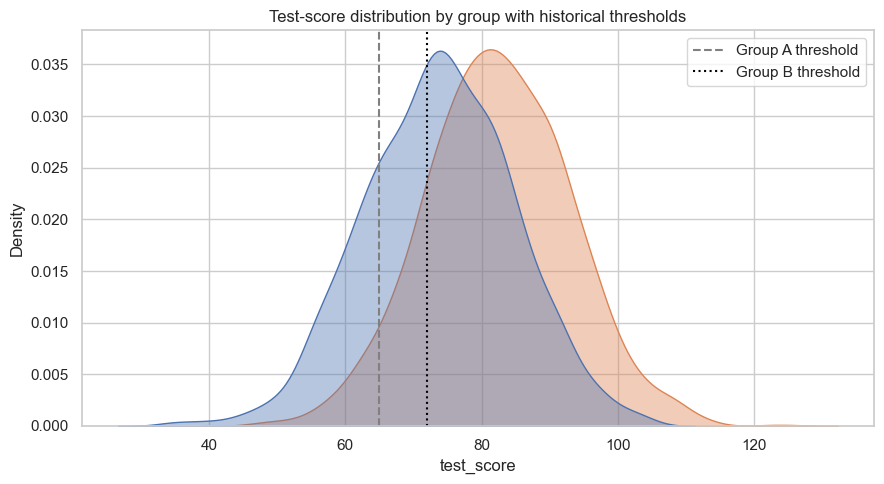

In [3]:
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df, x="test_score", hue="group", fill=True, common_norm=False, alpha=0.4)
plt.axvline(65, linestyle="--", color="gray", label="Group A threshold")
plt.axvline(72, linestyle=":", color="black", label="Group B threshold")
plt.title("Test-score distribution by group with historical thresholds")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Train a model without the protected attribute

We exclude `group` from the features. The model can still learn the bias through `test_score`, which
is correlated with group membership.

In [4]:
features = ["experience", "education", "test_score"]

X_train, X_temp, y_train, y_temp = train_test_split(
    df[features], df["hired"], test_size=0.4, random_state=RANDOM_STATE, stratify=df["group"]
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=df.loc[X_temp.index, "group"]
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)

test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
print("Overall test accuracy:", round((test_pred == y_test).mean(), 4))

Overall test accuracy: 0.9575


## 5. Fairness metrics

We compute group-level selection rates, true-positive rates, false-positive rates, demographic parity
gap, disparate impact ratio, and equal opportunity gap.

In [5]:
def group_metrics(y_true, y_pred, groups, positive_label=1):
    rows = []
    for group_name in sorted(groups.unique()):
        mask = groups == group_name
        yt = y_true[mask]
        yp = y_pred[mask]
        tp = np.sum((yp == 1) & (yt == 1))
        fn = np.sum((yp == 0) & (yt == 1))
        fp = np.sum((yp == 1) & (yt == 0))
        tn = np.sum((yp == 0) & (yt == 0))
        rows.append({
            "group": group_name,
            "n": int(mask.sum()),
            "selection_rate": float(np.mean(yp)),
            "tpr": float(tp / (tp + fn)) if (tp + fn) else np.nan,
            "fpr": float(fp / (fp + tn)) if (fp + tn) else np.nan,
            "accuracy": float(np.mean(yp == yt)),
        })
    return pd.DataFrame(rows)

test_groups = df.loc[X_test.index, "group"]
metrics_before = group_metrics(y_test.to_numpy(), test_pred, test_groups)
metrics_before.round(4)

,group,n,selection_rate,tpr,fpr,accuracy
0,A,484,0.9360,0.9805,0.000,0.9814
1,B,316,0.6582,1.0000,0.188,0.9209


In [6]:
def fairness_gaps(table):
    selection = table["selection_rate"]
    tpr = table["tpr"]
    return {
        "demographic_parity_gap": float(selection.max() - selection.min()),
        "disparate_impact_ratio": float(selection.min() / selection.max()),
        "equal_opportunity_gap": float(tpr.max() - tpr.min()),
    }

fairness_gaps(metrics_before)

{'demographic_parity_gap': 0.27772256512187476,
 'disparate_impact_ratio': 0.7032721379271801,
 'equal_opportunity_gap': 0.01948051948051943}

The model has a meaningful selection-rate gap and equal-opportunity gap even though `group` was not a
feature. The biased test score is acting as a proxy.

## 6. Post-processing: group-specific thresholds

One mitigation is to choose different decision thresholds per group so that selection rates are equal.
We choose thresholds on the validation set and evaluate on the test set.

This is a policy decision with legal and ethical implications; it is not automatically the right choice.

In [7]:
valid_prob = model.predict_proba(X_valid)[:, 1]
valid_groups = df.loc[X_valid.index, "group"]

target_rate = float(np.mean(valid_prob >= 0.5))
print("Target selection rate:", round(target_rate, 4))

thresholds = {}
for group_name in sorted(valid_groups.unique()):
    group_prob = valid_prob[valid_groups == group_name]
    thresholds[group_name] = float(np.quantile(group_prob, 1 - target_rate))

print("Group thresholds:", {k: round(v, 4) for k, v in thresholds.items()})

test_pred_adjusted = np.array([
    1 if probability >= thresholds[group_name] else 0
    for probability, group_name in zip(test_prob, test_groups)
])

metrics_after = group_metrics(y_test.to_numpy(), test_pred_adjusted, test_groups)
metrics_after.round(4)

Target selection rate: 0.82
Group thresholds: {'A': 0.9434, 'B': 0.0508}


,group,n,selection_rate,tpr,fpr,accuracy
0,A,484,0.8326,0.8723,0.0000,0.8781
1,B,316,0.8133,1.0000,0.5564,0.7658


In [8]:
print("Before:", {k: round(v, 4) for k, v in fairness_gaps(metrics_before).items()})
print("After: ", {k: round(v, 4) for k, v in fairness_gaps(metrics_after).items()})
print("Accuracy before:", round((test_pred == y_test).mean(), 4))
print("Accuracy after: ", round((test_pred_adjusted == y_test).mean(), 4))

Before: {'demographic_parity_gap': 0.2777, 'disparate_impact_ratio': 0.7033, 'equal_opportunity_gap': 0.0195}
After:  {'demographic_parity_gap': 0.0194, 'disparate_impact_ratio': 0.9768, 'equal_opportunity_gap': 0.1277}
Accuracy before: 0.9575
Accuracy after:  0.8338


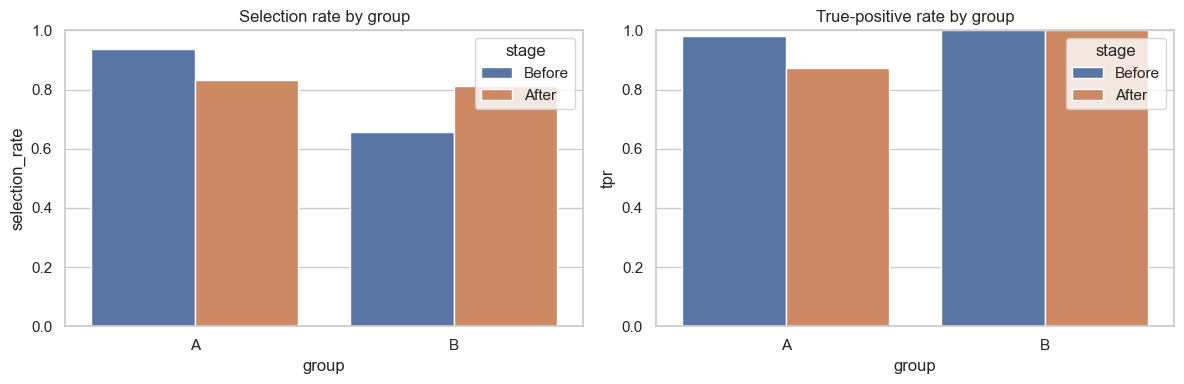

In [9]:
plot_df = pd.concat([
    metrics_before.assign(stage="Before"),
    metrics_after.assign(stage="After"),
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=plot_df, x="group", y="selection_rate", hue="stage", ax=axes[0])
axes[0].set_title("Selection rate by group")
axes[0].set_ylim(0, 1)

sns.barplot(data=plot_df, x="group", y="tpr", hue="stage", ax=axes[1])
axes[1].set_title("True-positive rate by group")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 7. Other mitigation strategies

### Pre-processing

- Rebalance or reweight training data.
- Remove or repair biased features.
- Collect better labels and more representative data.

### In-processing

- Add fairness constraints or penalties to the objective.
- Use adversarial debiasing or constrained optimisation.

### Post-processing

- Group-specific thresholds.
- Calibrate probabilities per group.
- Reject option or human review for uncertain cases.

Every approach has trade-offs. Always measure multiple metrics and involve stakeholders.

## 8. Model card

A model card documents:

- **Intended use** and out-of-scope uses.
- **Training data** and known limitations.
- **Evaluation data** and metrics, disaggregated by group.
- **Ethical considerations** and potential harms.
- **Fairness analysis** and mitigation choices.
- **Monitoring plan** and owners.

A model without documentation is hard to audit and easy to misuse.

## 9. Responsible AI checklist

- Define the decision and who is affected.
- Identify protected groups and relevant legal requirements.
- Measure fairness metrics on held-out data.
- Investigate proxy features and label quality.
- Document trade-offs and mitigation choices.
- Provide human review and appeal paths for high-stakes decisions.
- Monitor performance and fairness after deployment.
- Protect privacy and minimise data collection.

## Key takeaways

- Bias can persist even when the protected attribute is removed.
- Fairness has multiple, sometimes conflicting definitions.
- Measure group-level metrics, not only aggregate accuracy.
- Mitigation is a sociotechnical decision, not just a modelling trick.
- Documentation and monitoring are part of responsible deployment.

## Exercises

1. Add a proxy feature correlated with group and measure the fairness gap.
2. Compare demographic parity and equal opportunity before and after mitigation.
3. Evaluate the cost of mitigation in overall accuracy.
4. Write a one-page model card for this hiring model.
5. Research a real fairness audit and summarise its findings.
6. Discuss when group-specific thresholds might be inappropriate or illegal.